# Task 3 · Borderline Verification: Evidence & Fact-Checking
**Owner:** Meet Patel · DSA 4

**Research question:** How accurately can a lightweight NLI verifier (`DeBERTa-v3-base-mnli-fever-anli`) separate supported from unsupported/wrong answers, and how much unsafe error does it cut compared to LLM confidence alone?

**Kaggle settings:** **GPU T4 x2**, **Internet ON**. **Add Input → `dsa4-data` and `dsa4-cache`**.

### Scope of this Baseline Notebook (Day 2 Milestone)
1. Score both `direct` and `rag` answers in `dsa4-cache` against the top-5 retrieved Wikipedia passages using `NLISupportChecker` (individual passage scoring + `max` / `mean` aggregation).
2. Compare NLI support scores against cheap signals (`logprob_mean`, `-entropy_mean`, `top1_passage_score`) and a combined Logistic Regression verifier across all 3 seeded splits (`split_s0`, `split_s1`, `split_s2`, mean ± std on `test`).
3. Evaluate a **Selective Fact-Checking / Abstention** rule (threshold tuned on `val` for ≤10% and ≤5% wrong-pass rate, evaluated on `test`).
4. Evaluate a **Borderline Escalation Gate** (`direct` → verify with NLI → escalate to `rag` if unsupported) on accuracy vs. relative cost.
5. Break down performance on **TriviaQA (single-hop)** vs. **HotpotQA (multi-hop)** to quantify the multi-hop gap for Day 3 fine-tuning and evidence resolution.

In [1]:
# 1. Setup: clone repo, ensure src/dsa4/nli.py is present, install missing packages
import glob, os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/Naveena126/dsa4-reuse-retrieve-generate.git"
REPO_DIR = "/kaggle/working/repo"

if not os.path.exists(REPO_DIR):
    subprocess.run(["git", "clone", "-q", REPO_URL, REPO_DIR], check=True)
else:
    subprocess.run(["git", "-C", REPO_DIR, "pull", "-q"], check=True)

# Fallback if PR #5 (day1-meet) has not been merged into main yet
if not os.path.exists(f"{REPO_DIR}/src/dsa4/nli.py"):
    subprocess.run(["git", "-C", REPO_DIR, "fetch", "-q", "origin", "day1-meet"], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "checkout", "FETCH_HEAD", "--", "src/dsa4/nli.py"], check=True)

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentencepiece", "protobuf"], check=True)
os.chdir(REPO_DIR)
sys.path.insert(0, "src")

def find_input(name):
    hits = [h for h in glob.glob(f"/kaggle/input/**/{name}", recursive=True) if os.path.isdir(h)]
    if not hits:
        raise FileNotFoundError(f"Add the dataset {name} with Add Input")
    return hits[0]

DATA_DIR = find_input("dsa4-data")
CACHE_DIR = find_input("dsa4-cache")
OUT_DIR = Path("/kaggle/working/task3_baseline")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("DATA_DIR :", DATA_DIR)
print("CACHE_DIR:", CACHE_DIR)

DATA_DIR : /kaggle/input/datasets/sivapuramnaveena/dsa4-data
CACHE_DIR: /kaggle/input/datasets/sivapuramnaveena/dsa4-cache


In [2]:
# 2. Load questions (for seeded splits), passages, and shared cache
import json
import numpy as np
import pandas as pd
from dsa4 import data, index
from dsa4.cost import CostWeights

questions = data.load_questions(DATA_DIR)
passages = pd.read_json(Path(DATA_DIR) / "passages.jsonl", lines=True)

cache_path = sorted(Path(CACHE_DIR).rglob("cache.jsonl"))[0]
with open(cache_path, encoding="utf-8") as f:
    cache_recs = [json.loads(line) for line in f if line.strip()]

rows = []
for r in cache_recs:
    d, g = r["direct"], r["rag"]
    pids = [int(p) for p in g.get("passage_ids", []) if 0 <= int(p) < len(passages)]
    pscores = g.get("passage_scores", [])
    rows.append({
        "qid": r["qid"],
        "dataset": r["dataset"],
        "block": r["block"],
        "question": r["question"],
        "direct_answer": d["answer"],
        "direct_correct": int(bool(d["correct"])),
        "direct_logprob": float(d["logprob_mean"]),
        "direct_neg_entropy": -float(d["entropy_mean"]),
        "rag_answer": g["answer"],
        "rag_correct": int(bool(g["correct"])),
        "rag_logprob": float(g["logprob_mean"]),
        "rag_neg_entropy": -float(g["entropy_mean"]),
        "top1_retr_score": float(pscores[0]) if pscores else 0.0,
        "mean_retr_score": float(np.mean(pscores)) if pscores else 0.0,
        "passage_ids": pids,
    })

df = pd.DataFrame(rows).merge(
    questions[["qid", "split_s0", "split_s1", "split_s2"]],
    on="qid",
    how="inner",
)
print(f"Loaded {len(df)} cached questions across blocks {sorted(df['block'].unique().tolist())}")
print(df.groupby("dataset")[["direct_correct", "rag_correct"]].mean().round(4))

Loaded 1500 cached questions across blocks [1, 2, 4]
          direct_correct  rag_correct
dataset                              
hotpotqa          0.1827       0.4587
triviaqa          0.5320       0.7253


In [3]:
# 3. Run DeBERTa-v3-base NLI verification on direct and RAG answers (batched on GPU)
import time
from dsa4.nli import NLISupportChecker

checker = NLISupportChecker(batch_size=32)
print(f"Loaded {checker.model_name_or_path} on {checker.device} (entailment_idx={checker.entailment_idx})")

passage_lists = [
    [index.passage_text(passages.iloc[p]) for p in pids]
    for pids in df["passage_ids"]
]

t0 = time.time()
direct_items = list(zip(df["question"], df["direct_answer"], passage_lists))
direct_res = checker.score_batch(direct_items, aggregation="max")
t_direct = time.time() - t0

t0 = time.time()
rag_items = list(zip(df["question"], df["rag_answer"], passage_lists))
rag_res = checker.score_batch(rag_items, aggregation="max")
t_rag = time.time() - t0

df["nli_direct_max"] = [r["support_score"] for r in direct_res]
df["nli_direct_mean"] = [float(np.mean(r["passage_scores"])) if r["passage_scores"] else 0.0 for r in direct_res]
df["nli_rag_max"] = [r["support_score"] for r in rag_res]
df["nli_rag_mean"] = [float(np.mean(r["passage_scores"])) if r["passage_scores"] else 0.0 for r in rag_res]

# Save precomputed NLI scores for Day 3 reuse (no need to re-run DeBERTa)
df.drop(columns=["passage_ids"]).to_parquet(OUT_DIR / "nli_baseline_scores.parquet", index=False)
print(f"Scored {len(df)} direct answers in {t_direct:.1f}s ({1000*t_direct/len(df):.1f} ms/q)")
print(f"Scored {len(df)} RAG answers    in {t_rag:.1f}s ({1000*t_rag/len(df):.1f} ms/q)")

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.28k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  369MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loaded MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli on cuda (entailment_idx=0)
Scored 1500 direct answers in 55.4s (37.0 ms/q)
Scored 1500 RAG answers    in 60.7s (40.5 ms/q)


In [4]:
# 4. Discrimination benchmark (AUROC & AP) across 3 random splits (mean ± std on test)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def eval_signals(sub_df, target_col, signal_map, feat_cols):
    records = []
    for seed in (0, 1, 2):
        scol = f"split_s{seed}"
        tr = sub_df[sub_df[scol] == "train"]
        te = sub_df[sub_df[scol] == "test"]
        y_tr, y_te = tr[target_col].to_numpy(), te[target_col].to_numpy()

        for name, col in signal_map.items():
            s = te[col].fillna(0.0).to_numpy()
            records.append({
                "seed": seed, "method": name,
                "auroc": roc_auc_score(y_te, s),
                "ap": average_precision_score(y_te, s),
            })

        # Combined baseline: NLI + LLM confidence + retrieval score (fit on train only)
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        clf.fit(tr[feat_cols].fillna(0.0), y_tr)
        p_te = clf.predict_proba(te[feat_cols].fillna(0.0))[:, 1]
        records.append({
            "seed": seed, "method": "Combined (NLI + LogProb + Retr)",
            "auroc": roc_auc_score(y_te, p_te),
            "ap": average_precision_score(y_te, p_te),
        })

    res = pd.DataFrame(records).groupby("method", sort=False).agg(
        auroc_mean=("auroc", "mean"), auroc_std=("auroc", "std"),
        ap_mean=("ap", "mean"), ap_std=("ap", "std"),
    )
    return res

rag_signals = {
    "Retrieval top-1 score": "top1_retr_score",
    "LLM neg-entropy (RAG)": "rag_neg_entropy",
    "LLM logprob (RAG)": "rag_logprob",
    "DeBERTa NLI (mean top-5)": "nli_rag_mean",
    "DeBERTa NLI (max top-5)": "nli_rag_max",
}
rag_feats = ["nli_rag_max", "nli_rag_mean", "rag_logprob", "rag_neg_entropy", "top1_retr_score"]

print("=== RAG Answer Verification (All Questions, Test Mean ± Std over 3 Seeds) ===")
rag_table = eval_signals(df, "rag_correct", rag_signals, rag_feats)
display(rag_table.round(4))

print("\n=== Dataset Breakdown: TriviaQA (single-hop) vs. HotpotQA (multi-hop) ===")
for ds_name in ["triviaqa", "hotpotqa"]:
    sub = df[df["dataset"] == ds_name]
    tbl = eval_signals(sub, "rag_correct", rag_signals, rag_feats)
    print(f"\n--- {ds_name.upper()} (n={len(sub)}, RAG acc={sub['rag_correct'].mean():.3f}) ---")
    display(tbl.round(4))

=== RAG Answer Verification (All Questions, Test Mean ± Std over 3 Seeds) ===


,auroc_mean,auroc_std,ap_mean,ap_std
method,,,,
Retrieval top-1 score,0.5469,0.0127,0.6276,0.0089
LLM neg-entropy (RAG),0.7064,0.0141,0.7982,0.0147
LLM logprob (RAG),0.7043,0.0168,0.7968,0.0158
DeBERTa NLI (mean top-5),0.6160,0.0386,0.7116,0.0202
DeBERTa NLI (max top-5),0.6046,0.0361,0.6966,0.0205
Combined (NLI + LogProb + Retr),0.6964,0.0226,0.7653,0.0216



=== Dataset Breakdown: TriviaQA (single-hop) vs. HotpotQA (multi-hop) ===

--- TRIVIAQA (n=750, RAG acc=0.725) ---


,auroc_mean,auroc_std,ap_mean,ap_std
method,,,,
Retrieval top-1 score,0.6527,0.0398,0.8259,0.0325
LLM neg-entropy (RAG),0.7801,0.0314,0.9154,0.0234
LLM logprob (RAG),0.7760,0.0305,0.9137,0.0233
DeBERTa NLI (mean top-5),0.6690,0.0299,0.8345,0.0242
DeBERTa NLI (max top-5),0.6735,0.0339,0.8503,0.0365
Combined (NLI + LogProb + Retr),0.7928,0.0489,0.9119,0.0275



--- HOTPOTQA (n=750, RAG acc=0.459) ---


,auroc_mean,auroc_std,ap_mean,ap_std
method,,,,
Retrieval top-1 score,0.4951,0.0128,0.4654,0.0628
LLM neg-entropy (RAG),0.6609,0.0242,0.6742,0.0275
LLM logprob (RAG),0.6616,0.0323,0.6721,0.0278
DeBERTa NLI (mean top-5),0.5232,0.0445,0.5310,0.0185
DeBERTa NLI (max top-5),0.5130,0.0489,0.5026,0.0375
Combined (NLI + LogProb + Retr),0.6261,0.0217,0.5915,0.0189


In [5]:
# 5. Selective Fact-Checking Policy (tune threshold on val, evaluate on test)
def select_threshold(scores, y_true, max_wrong_pass=0.10):
    best_tau, best_cov = 1.01, 0.0
    for tau in np.linspace(0.0, 1.0, 201):
        accepted = scores >= tau
        cov = accepted.mean()
        if cov == 0:
            continue
        wrong_pass = (accepted & (y_true == 0)).mean()
        if wrong_pass <= max_wrong_pass and cov > best_cov:
            best_cov = cov
            best_tau = float(tau)
    return best_tau

def eval_selective_policy(sub_df, score_col, target_col, max_wrong_pass=0.10):
    rows = []
    for seed in (0, 1, 2):
        scol = f"split_s{seed}"
        va = sub_df[sub_df[scol] == "val"]
        te = sub_df[sub_df[scol] == "test"]
        tau = select_threshold(va[score_col].to_numpy(), va[target_col].to_numpy(), max_wrong_pass)
        acc_mask = te[score_col].to_numpy() >= tau
        y_te = te[target_col].to_numpy()
        cov = acc_mask.mean()
        sel_acc = y_te[acc_mask].mean() if acc_mask.any() else np.nan
        wrong_pass = (acc_mask & (y_te == 0)).mean()
        rows.append({"tau": tau, "coverage": cov, "selective_acc": sel_acc, "wrong_pass_rate": wrong_pass})
    return pd.DataFrame(rows).agg(["mean", "std"])

for cap in (0.10, 0.05):
    print(f"=== Selective Verification on RAG (Val target wrong-pass <= {cap:.0%}) ===")
    for name, col in [("LLM logprob", "rag_logprob"), ("DeBERTa NLI (max)", "nli_rag_max")]:
        stats = eval_selective_policy(df, col, "rag_correct", max_wrong_pass=cap)
        print(f"  {name:20s} | cov={stats.loc['mean','coverage']:.3f}±{stats.loc['std','coverage']:.3f} "
              f"| sel_acc={stats.loc['mean','selective_acc']:.3f}±{stats.loc['std','selective_acc']:.3f} "
              f"| wrong_pass={stats.loc['mean','wrong_pass_rate']:.3f}±{stats.loc['std','wrong_pass_rate']:.3f} "
              f"| tau={stats.loc['mean','tau']:.3f}")

=== Selective Verification on RAG (Val target wrong-pass <= 10%) ===
  LLM logprob          | cov=0.000±0.000 | sel_acc=nan±nan | wrong_pass=0.000±0.000 | tau=1.010
  DeBERTa NLI (max)    | cov=0.269±0.050 | sel_acc=0.701±0.008 | wrong_pass=0.081±0.017 | tau=0.942
=== Selective Verification on RAG (Val target wrong-pass <= 5%) ===
  LLM logprob          | cov=0.000±0.000 | sel_acc=nan±nan | wrong_pass=0.000±0.000 | tau=1.010
  DeBERTa NLI (max)    | cov=0.152±0.049 | sel_acc=0.709±0.077 | wrong_pass=0.043±0.014 | tau=0.980


In [6]:
# 6. Borderline Escalation Gate: Direct -> NLI Check -> Escalate to RAG if unsupported
weights = CostWeights(lookup=0.01, retrieval=0.10, call_3b=0.40, call_7b=1.00)
NLI_COST = 0.05  # lightweight 184M encoder relative to 7B LLM call (1.00)

gate_rows = []
for tau in np.linspace(0.0, 1.0, 21):
    # Accept direct if NLI supports it; otherwise escalate to RAG
    use_direct = df["nli_direct_max"].to_numpy() >= tau
    acc = np.where(use_direct, df["direct_correct"], df["rag_correct"]).mean()
    # Direct + retrieval + NLI check always paid; 2nd 7B call paid only on escalation
    cost = (
        weights.call_7b
        + weights.retrieval
        + NLI_COST
        + (1.0 - use_direct.mean()) * weights.call_7b
    )
    gate_rows.append({"tau": round(float(tau), 2), "keep_direct_rate": use_direct.mean(), "accuracy": acc, "avg_cost": cost})

gate_df = pd.DataFrame(gate_rows)
print(f"Always Direct: acc={df['direct_correct'].mean():.4f} | cost={weights.call_7b:.2f}")
print(f"Always RAG   : acc={df['rag_correct'].mean():.4f} | cost={weights.retrieval + weights.call_7b:.2f}")
print(f"Oracle (best): acc={np.maximum(df['direct_correct'], df['rag_correct']).mean():.4f}")
display(gate_df.iloc[::2].round(4))

Always Direct: acc=0.3573 | cost=1.00
Always RAG   : acc=0.5920 | cost=1.10
Oracle (best): acc=0.6387


,tau,keep_direct_rate,accuracy,avg_cost
0,0.0,1.0000,0.3573,1.1500
2,0.1,0.5533,0.5187,1.5967
4,0.2,0.4627,0.5420,1.6873
6,0.3,0.4180,0.5507,1.7320
8,0.4,0.3867,0.5520,1.7633
10,0.5,0.3540,0.5587,1.7960
12,0.6,0.3233,0.5647,1.8267
14,0.7,0.2893,0.5700,1.8607
16,0.8,0.2447,0.5780,1.9053
18,0.9,0.1967,0.5793,1.9533


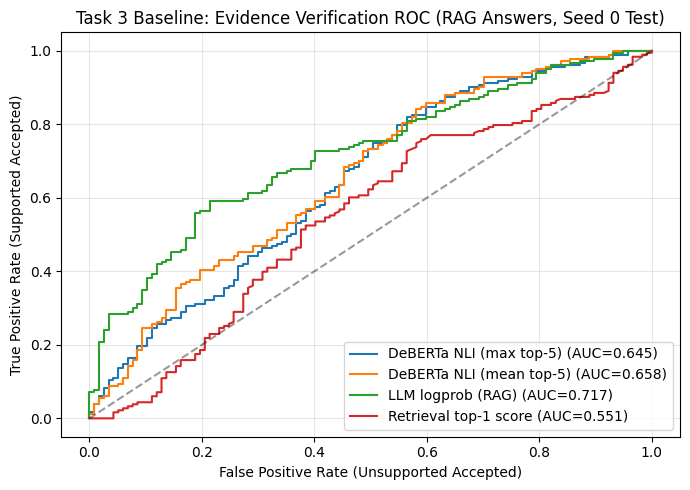

Saved outputs to: /kaggle/working/task3_baseline


In [7]:
# 7. Save baseline ROC comparison plot
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

te0 = df[df["split_s0"] == "test"]
y = te0["rag_correct"].to_numpy()

plt.figure(figsize=(7, 5))
for label, col in [
    ("DeBERTa NLI (max top-5)", "nli_rag_max"),
    ("DeBERTa NLI (mean top-5)", "nli_rag_mean"),
    ("LLM logprob (RAG)", "rag_logprob"),
    ("Retrieval top-1 score", "top1_retr_score"),
]:
    fpr, tpr, _ = roc_curve(y, te0[col].fillna(0.0))
    auc = roc_auc_score(y, te0[col].fillna(0.0))
    plt.plot(fpr, tpr, label=f"{label} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("False Positive Rate (Unsupported Accepted)")
plt.ylabel("True Positive Rate (Supported Accepted)")
plt.title("Task 3 Baseline: Evidence Verification ROC (RAG Answers, Seed 0 Test)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "roc_comparison.png", dpi=150)
plt.show()
print("Saved outputs to:", OUT_DIR)